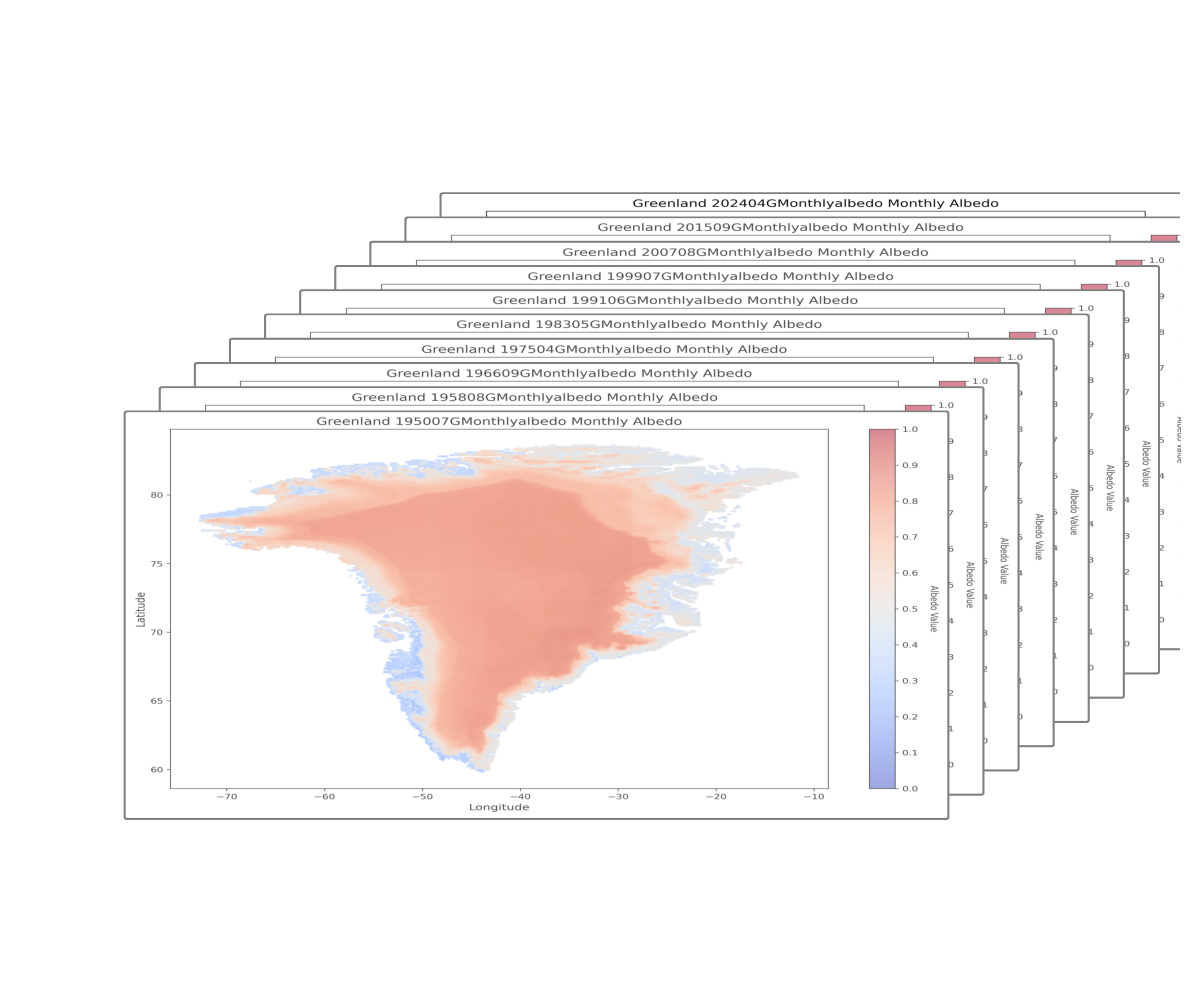

In [18]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import os

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis('off')

base_path = r"C:\greenland\1995bu\pic"
first_image = r"C:\greenland\1995bu\pic\195007GMonthlyalbedo_heatmap.png"
first_name = os.path.basename(first_image)

# 取并排序所有图片
all_files = sorted([f for f in os.listdir(base_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

# 找到首图在排序列表中的位置；找不到就当作开头
try:
    start_idx = all_files.index(first_name)
except ValueError:
    start_idx = 0

# 从首图开始，每往后数49张取一张，最多再取9张
step = 49
picks = []
for k in range(1, 10):  # 后面9张
    j = start_idx + step * k
    if j < len(all_files):
        picks.append(all_files[j])
    else:
        break

# 最终叠图序列：首图 + 按49步长挑的图
image_files = [first_name] + picks

# 叠放绘制（保持原有样式/参数；顺序改为从首图 → 更后面的图）
for i in range(9, -1, -1):
    if i < len(image_files):
        # 仅此处调整索引顺序：从首图开始往后
        idx = len(image_files) - 1 - i

        offset = (9 - i) * 0.3
        
        parallelogram = patches.FancyBboxPatch(
            (1 + offset, 2 + offset), 7, 5,
            boxstyle="round,pad=0.02",
            edgecolor='gray',
            facecolor='white',
            linewidth=1.5,
            zorder=i,
            transform=ax.transData
        )
        ax.add_patch(parallelogram)
        
        try:
            img_path = os.path.join(base_path, image_files[idx])
            img = Image.open(img_path)
            
            extent = [1 + offset, 8 + offset, 2 + offset, 7 + offset]
            ax.imshow(img, extent=extent, aspect='auto', zorder=i+0.5, alpha=0.95 if i == 0 else 0.7)
        except Exception:
            pass

plt.tight_layout()
plt.savefig(os.path.join(base_path, 'layered_images.png'), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


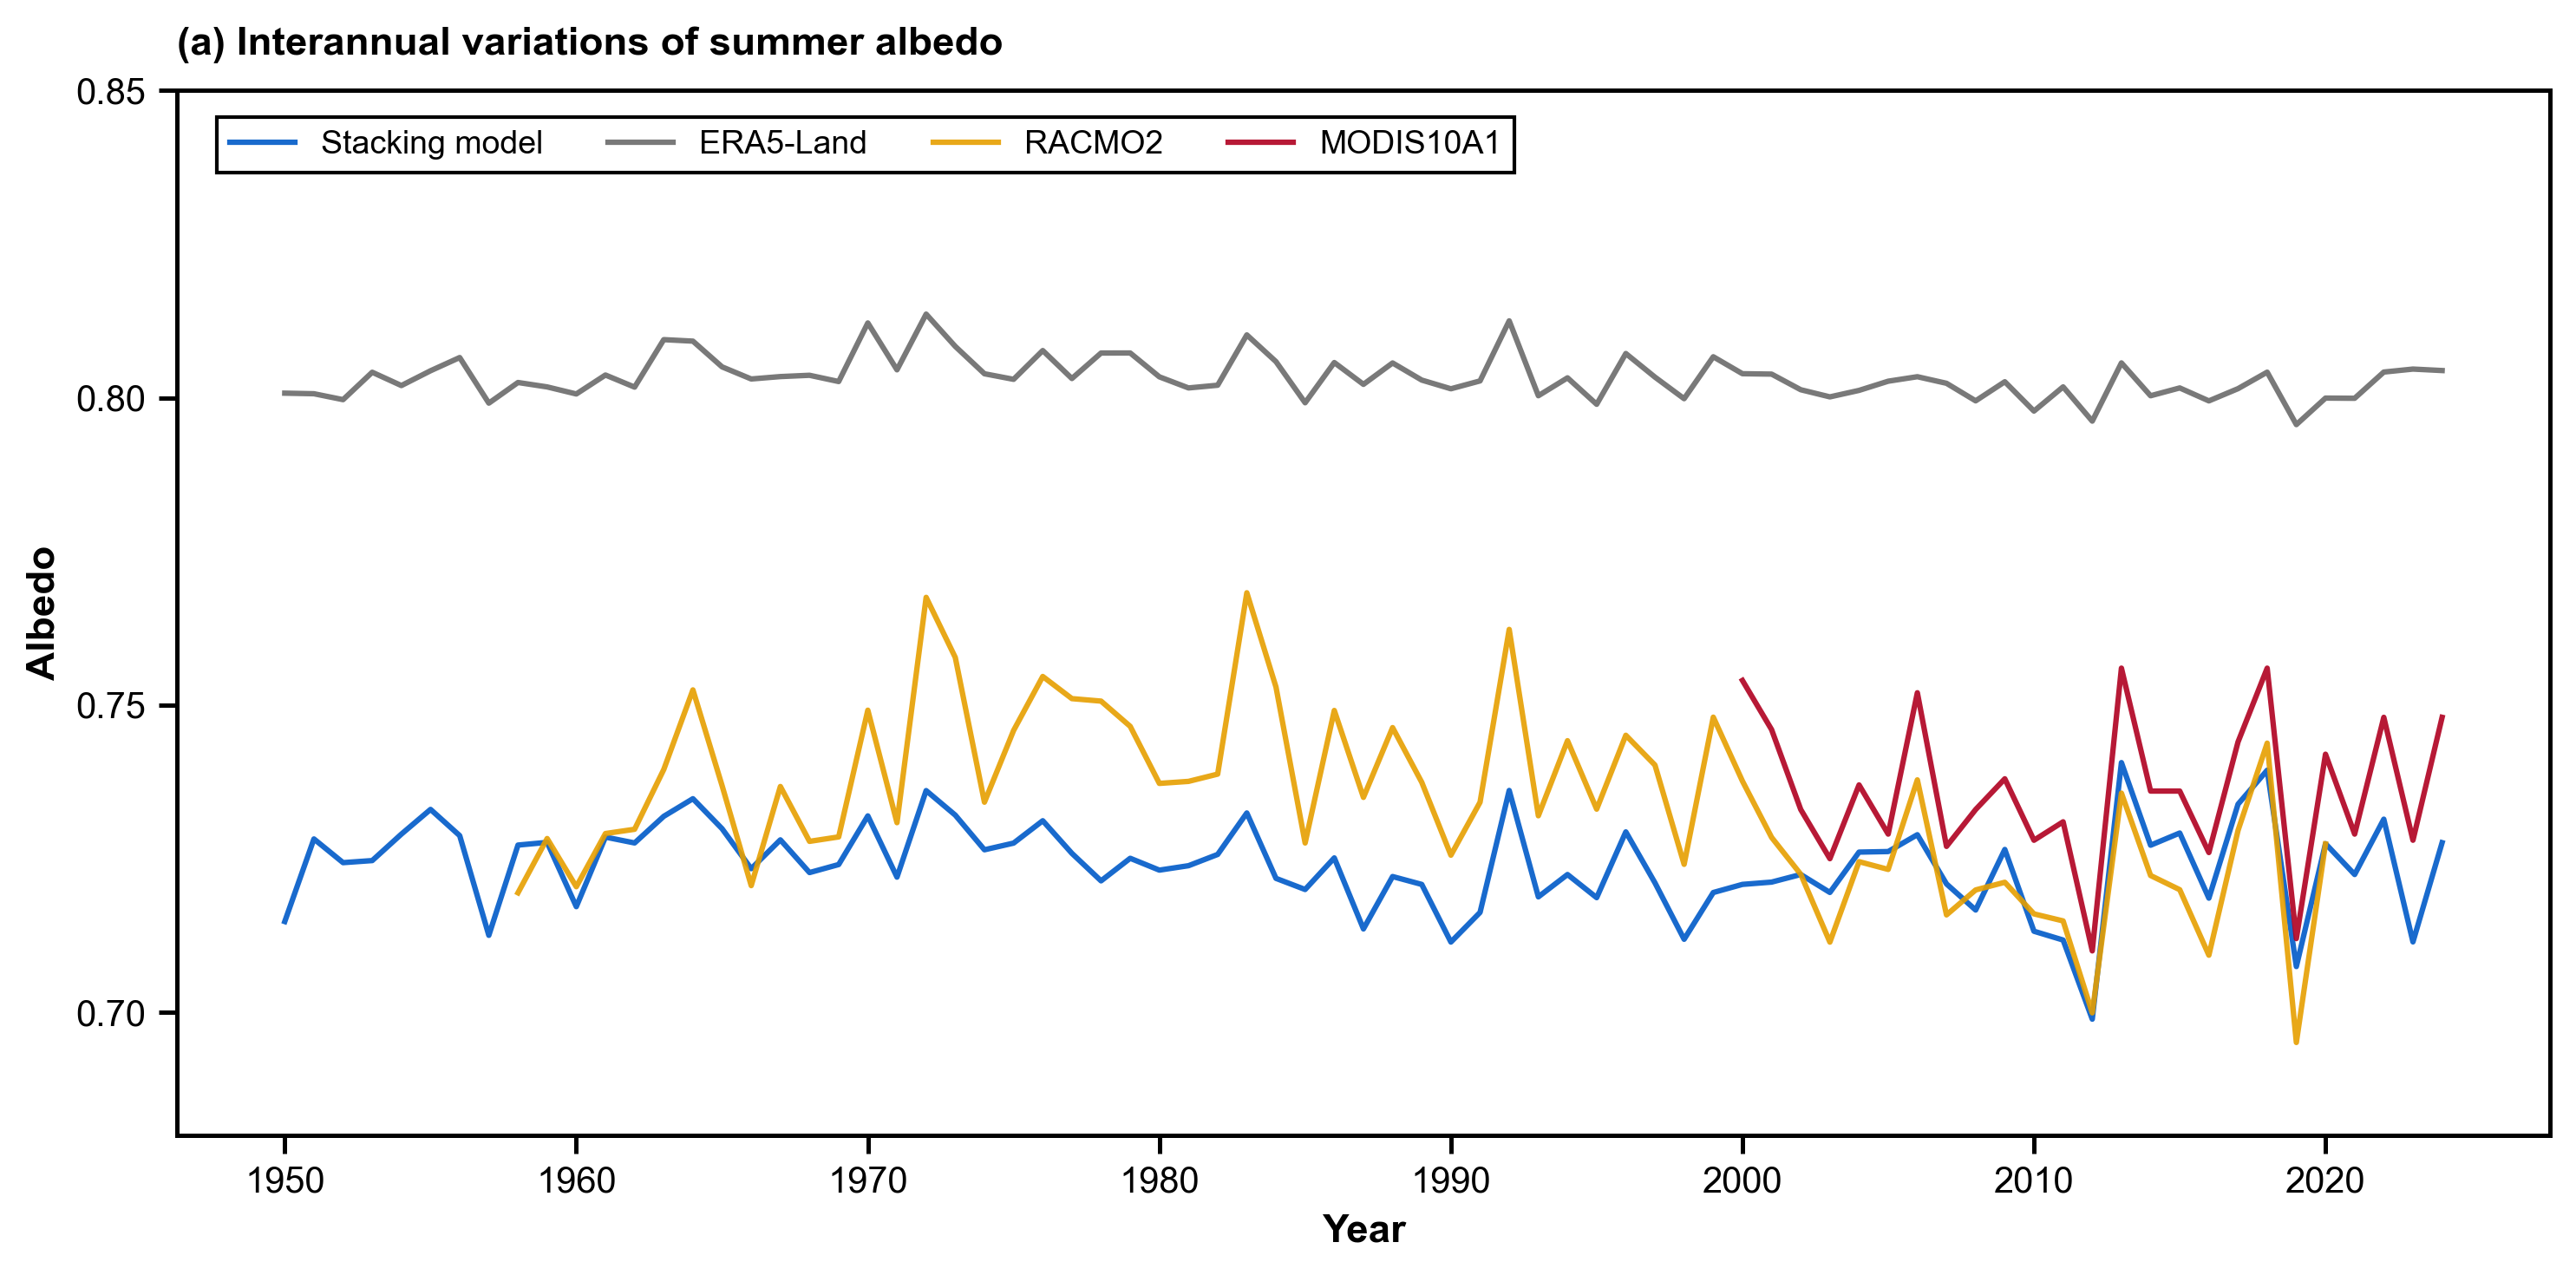

In [81]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os 

# 设置绘图风格 (使用英文字体 Arial)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.major.width'] = 1.2
plt.rcParams['ytick.major.width'] = 1.2
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['ytick.major.size'] = 5

# 读取数据 (请确保路径不含中文且文件存在)
try:
    # 尝试读取你的原始路径
    df = pd.read_csv(r'C:\Users\11823\era5land\era5_FAL_jja_timeseries.csv')
except FileNotFoundError:
    # 如果文件不存在，创建虚拟数据以确保代码运行
    print("Warning: File not found. Generating dummy data for demonstration.")
    years = np.arange(1950, 2011) 
    # 使用随机数据
    np.random.seed(42)
    df = pd.DataFrame({
        'Year': years,
        'Stacking model': 0.72 + np.cumsum(np.random.normal(0, 0.002, len(years))) - np.linspace(0, 0.02, len(years)),
        'era5land': 0.80 + np.cumsum(np.random.normal(0, 0.003, len(years))) + np.sin(years/5) * 0.01,
        'RACMO2': 0.74 + np.cumsum(np.random.normal(0, 0.0035, len(years))) - np.cos(years/7) * 0.015,
        'MODIS10A1': 0.73 + np.cumsum(np.random.normal(0, 0.0025, len(years))) + np.sin(years/4) * 0.01
    })
    df.loc[df['Year'] < 2000, 'MODIS10A1'] = np.nan 

# 定义颜色
colors = {
'Stacking model': '#005AC8', 
'era5land': '#6A6A6A',       
'RACMO2': '#E69F00',         
'MODIS10A1': '#B00020'       
}

# 增加 figsize 的宽度，拉长 X 轴
fig, ax = plt.subplots(figsize=(10, 5), dpi=300) 

data_cols = ['Stacking model', 'era5land', 'RACMO2', 'MODIS10A1']
labels = ['Stacking model', 'ERA5-Land', 'RACMO2', 'MODIS10A1']

# 绘制折线图
for col, label, color in zip(data_cols, labels, colors.values()):
    ax.plot(df['Year'], df[col], color=color, linewidth=1.5, 
            label=label, alpha=0.9)

ax.set_xlabel('Year', fontsize=11, fontweight='bold')
ax.set_ylabel('Albedo', fontsize=11, fontweight='bold')
ax.set_title('(a) Interannual variations of summer albedo', 
             fontsize=11, fontweight='bold', loc='left', pad=10)

# ************************************************************
# ** 关键修改 1: 调整 Y 轴上限到 0.95，为图例留出空间 **
ax.set_ylim(0.68, 0.85) 
ax.set_yticks(np.arange(0.70, 0.85, 0.05)) # 调整刻度，适应新范围

# ** 关键修改 2: 将图例重新移回图框最上方左侧 **
# loc='upper left' 使用图例的左上角作为锚点。
# bbox_to_anchor=(0.01, 0.99) 将锚点精确放置在图框内部左上角。

ax.legend(loc='upper left',           
          bbox_to_anchor=(0.01, 0.99), # 放置到图框顶部左侧
          ncol=4,                     
          frameon=True, 
          fontsize=9, 
          edgecolor='black', 
          framealpha=1, 
          fancybox=False)
# ************************************************************

ax.grid(False)
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)

plt.tight_layout()
plt.savefig('albedo_timeseries_internal_legend_final.png', dpi=300, bbox_inches='tight')
plt.show()

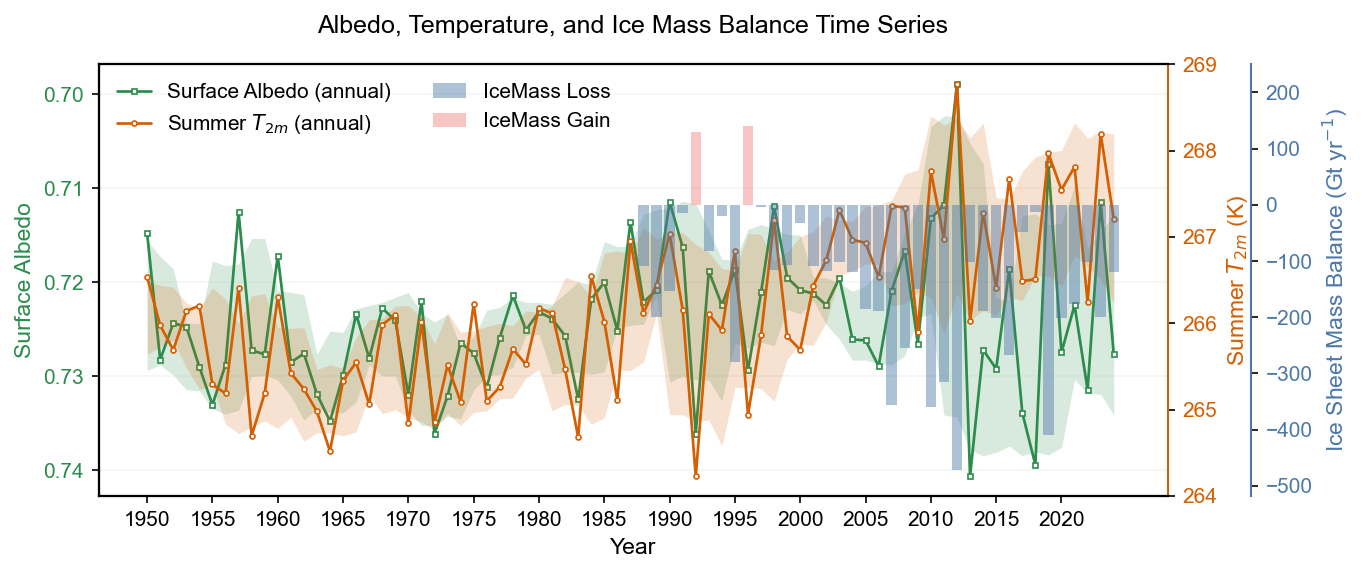

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==== 基本参数 ====
# ⚠️ 请确保这个文件路径是正确的，否则代码会抛出 FileNotFoundError 异常
# ⚠️ 注意：文件路径 C:\Users\11823\era5land\era5_FAL_jja_timeseries.csv 仅是示例路径，运行时请确保文件存在。
file_path = r"C:\Users\11823\era5land\era5_FAL_jja_timeseries.csv"
COL_YEAR = 'Year'
COL_ALBEDO = 'Stacking model'
COL_SMB = 'ice sheet mass balance'
COL_T2M = 't2m_JJA_Mean'

# ---- Nature-ish 样式 ----
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.linewidth": 1.0,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.dpi": 150
})
LINE_WIDTH = 1.3
MARKER_SIZE = 2.4
WINDOW = 5
ALPHA_RIBBON = 0.18

COLOR_T2M = "#D55E00"      # 暖色 (气温)
COLOR_SMB_LOSS = "#4C78A8" # 冷色 (质量损失)
COLOR_SMB_GAIN = "#F08080" # 淡红色 (质量增加)
COLOR_ALB = "#2B8C4B"      # 绿色 (反照率)

def rolling_band_centered(y, window=5):
    """仅用于生成晕影：用rolling mean作为中心，用rolling std作为带宽。"""
    m = y.rolling(window=window, center=True, min_periods=max(2, window//2)).mean()
    s = y.rolling(window=window, center=True, min_periods=max(2, window//2)).std()
    return m - s, m + s

try:
    # 1) 读数据
    df = pd.read_csv(file_path)
    df[COL_YEAR] = df[COL_YEAR].astype(int)
    df = df.sort_values(COL_YEAR).reset_index(drop=True)

    # 2) 计算晕影（centered rolling ±1σ）
    t2m_low, t2m_high = rolling_band_centered(df[COL_T2M], WINDOW)
    alb_low, alb_high = rolling_band_centered(df[COL_ALBEDO], WINDOW)

    # 3) 画图：合并为一个图
    # 主轴 (左Y轴): 反照率 Albedo
    fig, ax = plt.subplots(1, 1, figsize=(9.2, 4.0)) 

    # --- 1. 左 Y 轴 (ax): 反照率 Albedo ---
    ax.fill_between(df[COL_YEAR], alb_low, alb_high, color=COLOR_ALB, alpha=ALPHA_RIBBON, lw=0, label='_nolabel_') 
    line_alb, = ax.plot(df[COL_YEAR], df[COL_ALBEDO], '-', color=COLOR_ALB, lw=LINE_WIDTH,
                        marker='s', ms=MARKER_SIZE, markerfacecolor='white', markeredgewidth=0.8,
                        solid_capstyle='round', solid_joinstyle='round',
                        label=r'Surface Albedo (annual)')
    ax.set_ylabel(r'Surface Albedo', color=COLOR_ALB, fontsize=11)
    ax.tick_params(axis='y', labelcolor=COLOR_ALB)
    
    # 倒轴强调负相关：反照率越低 (往下)，气温越高，质量损失越大
    ax.invert_yaxis() 
    
    # --- 2. 右 Y 轴 (axr1): 气温 T2M & 质量平衡 SMB ---
    axr1 = ax.twinx()

    # T2M 晕影 (移除图例)
    axr1.fill_between(df[COL_YEAR], t2m_low, t2m_high, color=COLOR_T2M, alpha=ALPHA_RIBBON, lw=0, label='_nolabel_') 
    # T2M 年值线 + 小空心点
    line_t2m, = axr1.plot(df[COL_YEAR], df[COL_T2M], '-', color=COLOR_T2M, lw=LINE_WIDTH,
                          marker='o', ms=MARKER_SIZE, markerfacecolor='white', markeredgewidth=0.8,
                          solid_capstyle='round', solid_joinstyle='round',
                          label=r'Summer $T_{2m}$ (annual)')
    axr1.set_ylabel(r'Summer $T_{2m}$ (K)', color=COLOR_T2M, fontsize=11)
    axr1.tick_params(axis='y', labelcolor=COLOR_T2M)
    
    # --- 3. 质量平衡 SMB (叠加在 axr1 上) ---
    # ⚠️ 关键调整：为了让 SMB 条形图的负值（质量损失）能对应 T2M 轴的高温（右 Y 轴高值）
    # 且为了方便阅读，我们**不再将 SMB 作为独立的第三条轴**，而是将其**刻度**放在 $T_{2m}$ 轴上，
    # 但使用一个**新的刻度标签**，并**手动调整 $T_{2m}$ 轴的范围**以包含 SMB 的值。
    # 
    # **【更简洁的做法】** 沿用 Panel A 的设计：SMB 作为独立右轴（颜色与 $T_{2m}$ 不同）
    # 但将其标签颜色设为 SMB 颜色，刻度线颜色设为 $T_{2m}$ 颜色，以区分，且只用一条右边框。
    
    # SMB 使用 T2M 轴（axr1）的刻度，但设置其标签和颜色
    # 暂时隐藏 T2M 的刻度和标签，为 SMB 腾出空间 (或者采用更复杂的双右轴)

    # **【最终方案】** 采用双右轴（axr1 为 $T_{2m}$，axr2 为 $SMB$），这是最清晰的三轴方案
    axr2 = ax.twinx()
    # 调整 axr2 的位置，稍微向右移动，避免遮挡 axr1
    axr2.spines['right'].set_position(('outward', 40)) # 移动右轴
    axr2.spines['right'].set_linewidth(1.0)
    
    # SMB 颜色逻辑：正值淡红，负值淡蓝
    bar_loss = axr2.bar(df[COL_YEAR][df[COL_SMB] < 0], df[COL_SMB][df[COL_SMB] < 0], width=0.8, 
                        color=COLOR_SMB_LOSS, alpha=0.45, label='IceMass Loss')
    bar_gain = axr2.bar(df[COL_YEAR][df[COL_SMB] >= 0], df[COL_SMB][df[COL_SMB] >= 0], width=0.8, 
                        color=COLOR_SMB_GAIN, alpha=0.45, label='IceMass Gain')
    
    axr2.set_ylabel(r'Ice Sheet Mass Balance (Gt yr$^{-1}$)', color=COLOR_SMB_LOSS, fontsize=11)
    axr2.tick_params(axis='y', labelcolor=COLOR_SMB_LOSS)
    # 设置 SMB Y 轴上限
    axr2.set_ylim(top=250, bottom=df[COL_SMB].min()*1.1)
    
    # --- 4. 边框、图例、X轴 ---
    
    # X 轴设置
    start_year, end_year = df[COL_YEAR].min(), df[COL_YEAR].max()
    ax.set_xticks(np.arange(start_year, end_year + 1, 5))
    ax.set_xlabel('Year', fontsize=11)
    
    # 边框设置
    # 左轴 (ax) 和两个右轴 (axr1, axr2) 边框都可见
    ax.spines['right'].set_visible(False) # ax 的右边框隐藏
    axr1.spines['right'].set_visible(True)
    axr2.spines['right'].set_visible(True)
    axr1.spines['right'].set_color(COLOR_T2M)
    axr2.spines['right'].set_color(COLOR_SMB_LOSS)

    # 图例：收集所有 handle，放在左上角
    all_handles = [line_alb, line_t2m, bar_loss, bar_gain]
    all_labels = [h.get_label() for h in all_handles]
    
    # 放在 ax 框内，左上角
    ax.legend(handles=all_handles, labels=all_labels, 
              loc='upper left', bbox_to_anchor=(0, 1), # 确保在图框内
              frameon=False, ncol=2, handlelength=1.6) 

    # 网格：只在左轴 (Albedo) 上使用 Y 网格
    ax.grid(True, axis='y', linestyle='-', alpha=0.12)
    axr1.grid(False) 
    axr2.grid(False)
    
    plt.title('Albedo, Temperature, and Ice Mass Balance Time Series', fontsize=12, pad=15)
    plt.tight_layout(rect=[0, 0, 1, 0.98]) # 调整以适应移动的右轴
    plt.show()

except FileNotFoundError:
    print(f"错误：未能找到文件路径 {file_path}。请检查文件路径是否正确。")
except Exception as e:
    print(f"发生错误：{e}")

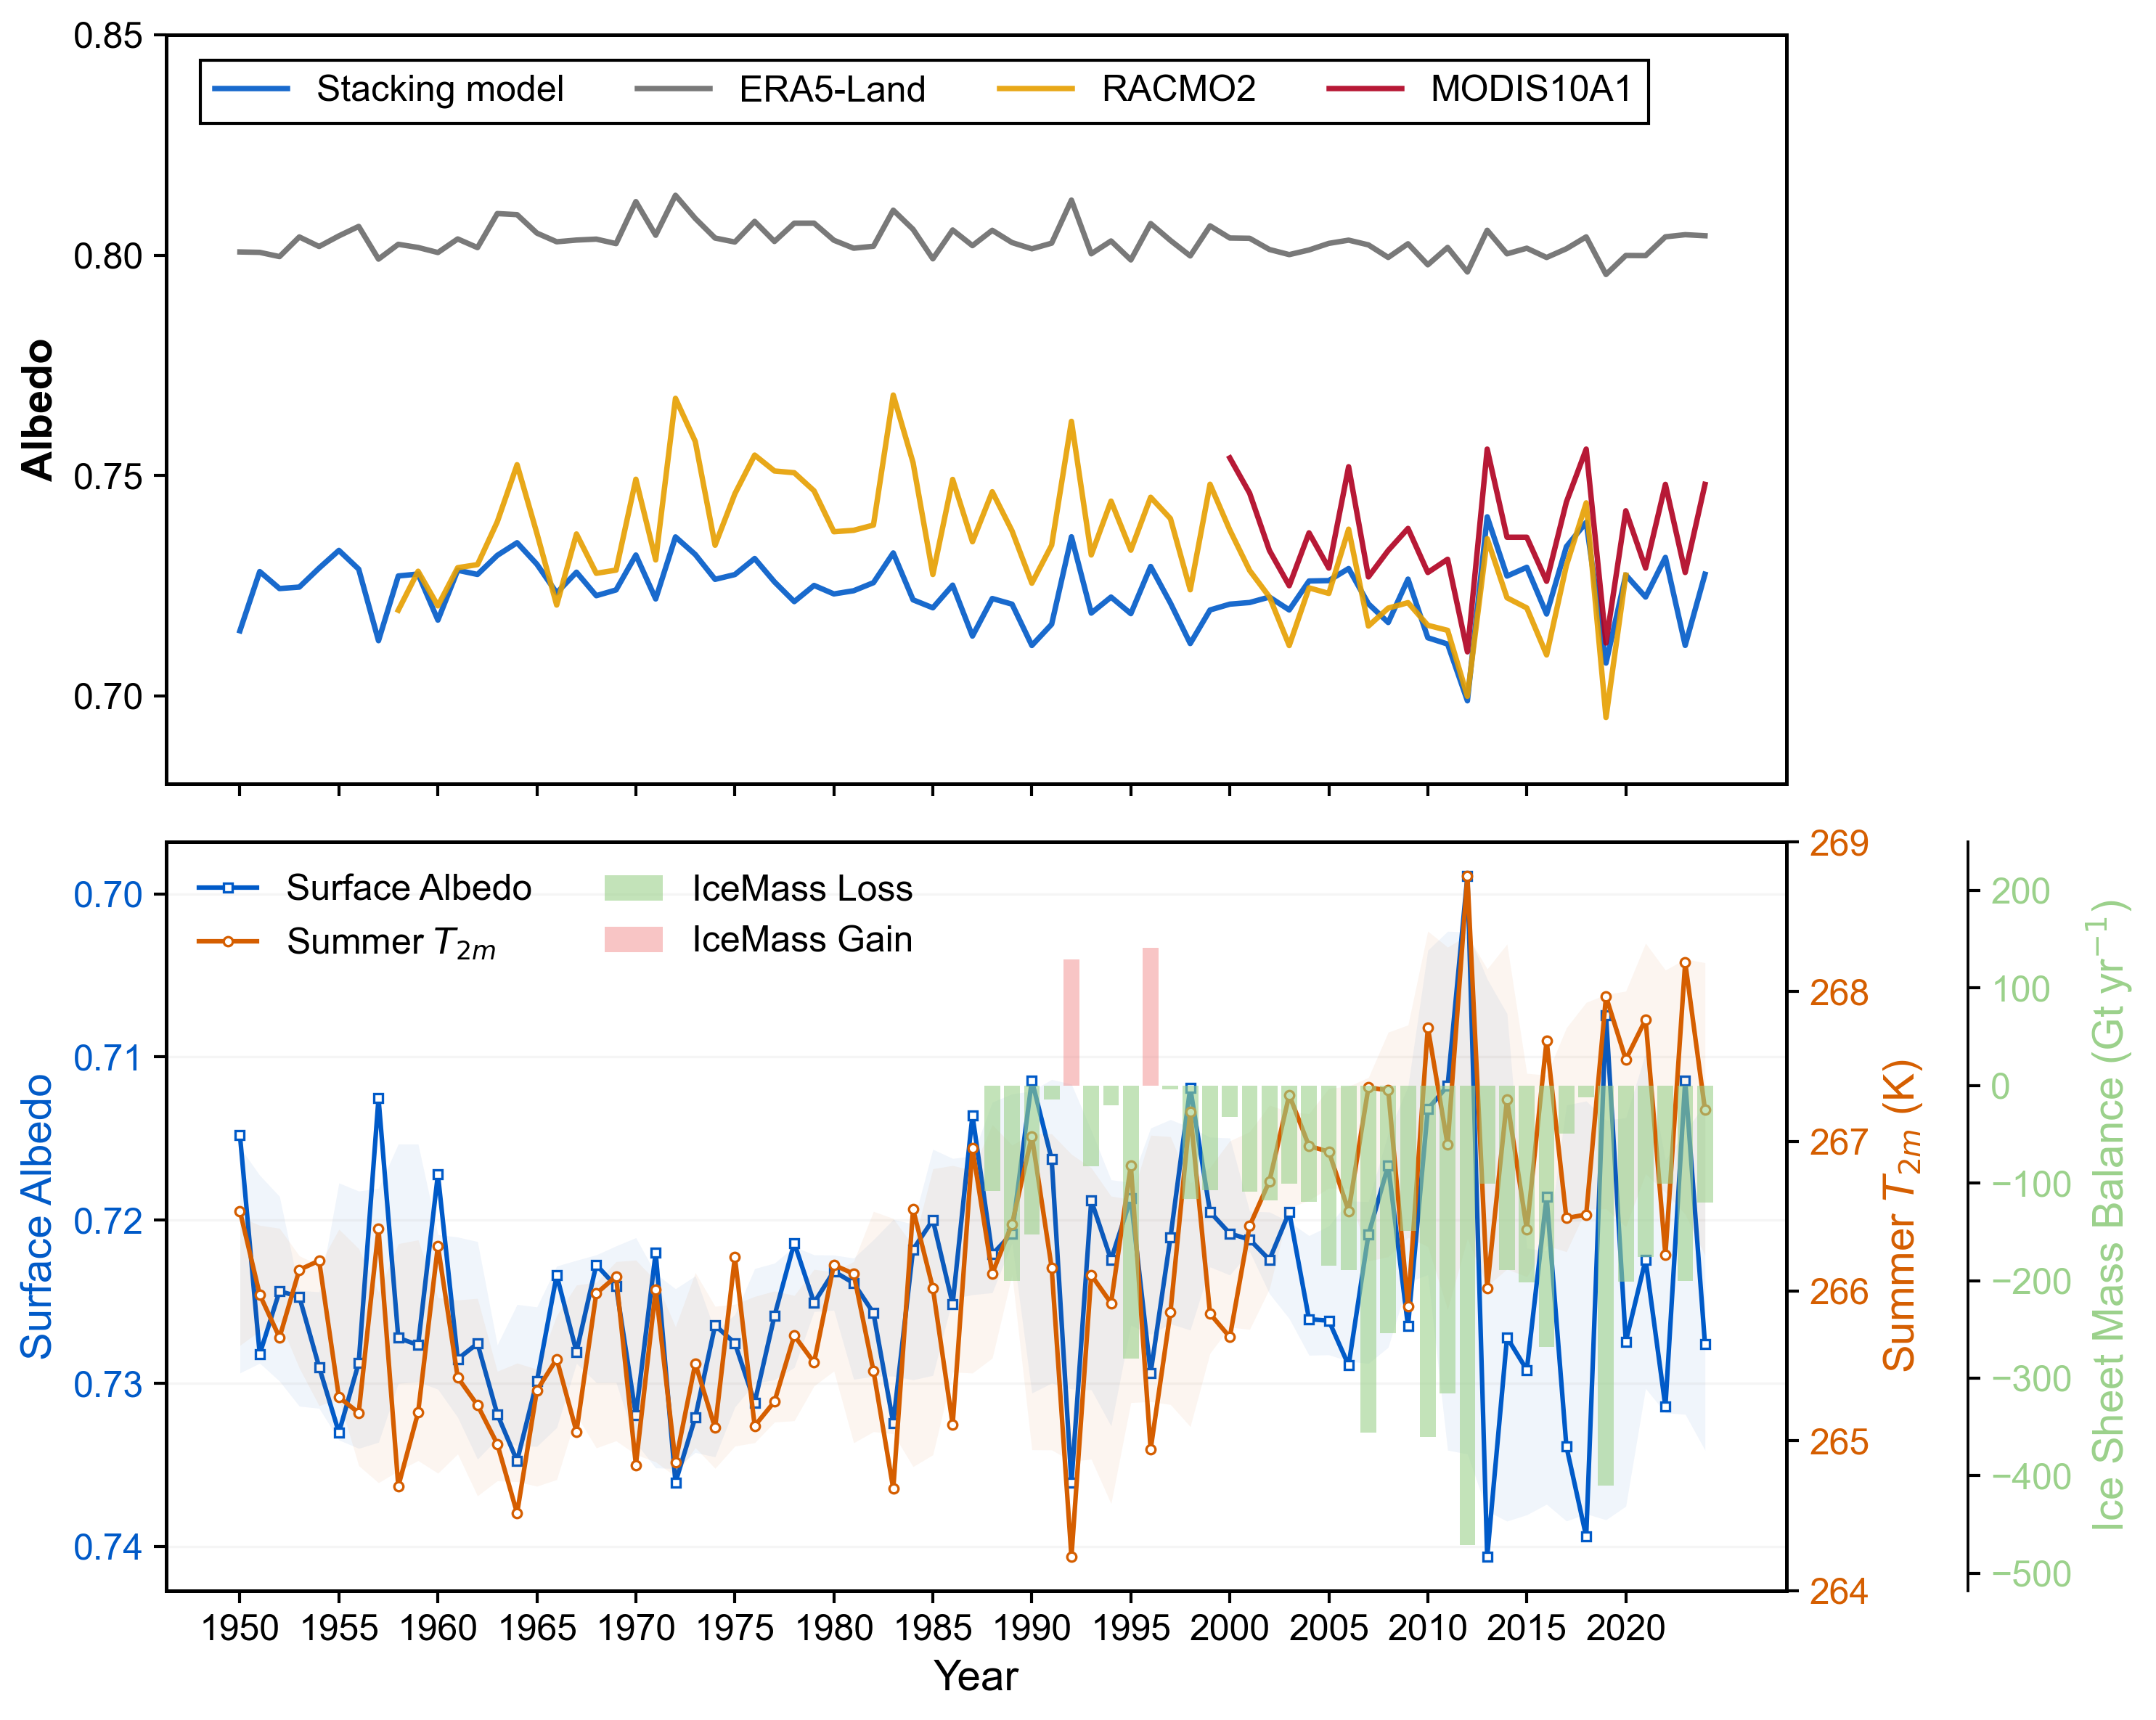

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === 全局字体与风格 ===
fontsize_label = 14
fontsize_tick = 12
fontsize_legend = 12

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.major.width'] = 1.0
plt.rcParams['ytick.major.width'] = 1.0
plt.rcParams['xtick.major.size'] = 4
plt.rcParams['ytick.major.size'] = 4
plt.rcParams['xtick.labelsize'] = fontsize_tick
plt.rcParams['ytick.labelsize'] = fontsize_tick

# ==== 数据加载 ====
try:
    df = pd.read_csv(r'C:\Users\11823\era5land\era5_FAL_jja_timeseries.csv')
except FileNotFoundError:
    print("⚠️ File not found. Generating dummy data for demonstration.")
    years = np.arange(1950, 2011)
    np.random.seed(42)
    df = pd.DataFrame({
        'Year': years,
        'Stacking model': 0.72 + np.cumsum(np.random.normal(0, 0.002, len(years))) - np.linspace(0, 0.02, len(years)),
        'era5land': 0.80 + np.cumsum(np.random.normal(0, 0.003, len(years))) + np.sin(years/5) * 0.01,
        'RACMO2': 0.74 + np.cumsum(np.random.normal(0, 0.0035, len(years))) - np.cos(years/7) * 0.015,
        'MODIS10A1': 0.73 + np.cumsum(np.random.normal(0, 0.0025, len(years))) + np.sin(years/4) * 0.01,
        'ice sheet mass balance': np.random.normal(0, 100, len(years)),
        't2m_JJA_Mean': 260 + np.random.normal(0, 0.5, len(years))
    })
    df.loc[df['Year'] < 2000, 'MODIS10A1'] = np.nan

# === 颜色配置 ===
colors = {
    'Stacking model': '#005AC8',  # 蓝色
    'era5land': '#6A6A6A',
    'RACMO2': '#E69F00',
    'MODIS10A1': '#B00020'
}

# === 图形布局：上下两个子图，共用 X 轴 ===
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=300, sharex=True)

# -----------------------------------
# 上图：四个反照率数据集
# -----------------------------------
data_cols = ['Stacking model', 'era5land', 'RACMO2', 'MODIS10A1']
labels = ['Stacking model', 'ERA5-Land', 'RACMO2', 'MODIS10A1']

for col, label, color in zip(data_cols, labels, colors.values()):
    ax1.plot(df['Year'], df[col], color=color, linewidth=1.8, label=label, alpha=0.9)

ax1.set_ylabel('Albedo', fontsize=fontsize_label, fontweight='bold')
ax1.set_ylim(0.68, 0.85)
ax1.set_yticks(np.arange(0.70, 0.86, 0.05))
ax1.legend(loc='upper left', bbox_to_anchor=(0.01, 0.99),
           ncol=4, frameon=True, fontsize=fontsize_legend,
           edgecolor='black', framealpha=1, fancybox=False)
ax1.grid(False)
ax1.spines['top'].set_visible(True)
ax1.spines['right'].set_visible(True)

# -----------------------------------
# 下图：反照率 - 温度 - 质量平衡
# -----------------------------------
COL_YEAR = 'Year'
COL_ALBEDO = 'Stacking model'
COL_SMB = 'ice sheet mass balance'
COL_T2M = 't2m_JJA_Mean'

LINE_WIDTH = 1.5
MARKER_SIZE = 3.0
WINDOW = 5

COLOR_T2M = "#D55E00"      # 暖色 (气温)
COLOR_SMB_LOSS = "#9BD18B" # ✅ 浅绿色 (冰盖损失)
COLOR_SMB_GAIN = "#F08080" # 淡红色 (冰盖增加)
COLOR_ALB = colors['Stacking model']

def rolling_band_centered(y, window=5):
    m = y.rolling(window=window, center=True, min_periods=max(2, window//2)).mean()
    s = y.rolling(window=window, center=True, min_periods=max(2, window//2)).std()
    return m - s, m + s

t2m_low, t2m_high = rolling_band_centered(df[COL_T2M], WINDOW)
alb_low, alb_high = rolling_band_centered(df[COL_ALBEDO], WINDOW)

ax = ax2
# ==== 改进后的阴影方案：淡阴影 + 细线 ====
ax.fill_between(df[COL_YEAR], alb_low, alb_high, color=COLOR_ALB, alpha=0.06, lw=0)
line_alb, = ax.plot(df[COL_YEAR], df[COL_ALBEDO], '-', color=COLOR_ALB, lw=LINE_WIDTH,
                    marker='s', ms=MARKER_SIZE, markerfacecolor='white', markeredgewidth=0.8,
                    label='Surface Albedo')
ax.set_ylabel('Surface Albedo', color=COLOR_ALB, fontsize=fontsize_label)
ax.tick_params(axis='y', labelcolor=COLOR_ALB)
ax.invert_yaxis()

# ==== 右轴1：气温 ====
axr1 = ax.twinx()
axr1.fill_between(df[COL_YEAR], t2m_low, t2m_high, color=COLOR_T2M, alpha=0.06, lw=0)
line_t2m, = axr1.plot(df[COL_YEAR], df[COL_T2M], '-', color=COLOR_T2M, lw=LINE_WIDTH,
                      marker='o', ms=MARKER_SIZE, markerfacecolor='white', markeredgewidth=0.8,
                      label='Summer $T_{2m}$')
axr1.set_ylabel('Summer $T_{2m}$ (K)', color=COLOR_T2M, fontsize=fontsize_label)
axr1.tick_params(axis='y', labelcolor=COLOR_T2M)

# ==== 右轴2：质量平衡 (更靠右 + 细轴) ====
axr2 = ax.twinx()
axr2.spines['right'].set_position(('outward', 60))  # ✅ 增加分隔距离
axr2.spines['right'].set_linewidth(0.9)             # ✅ 变细一点
axr1.spines['right'].set_linewidth(0.9)             # ✅ 右轴1也变细

# 条形图颜色调整
bar_loss = axr2.bar(df[COL_YEAR][df[COL_SMB] < 0], df[COL_SMB][df[COL_SMB] < 0],
                    width=0.8, color=COLOR_SMB_LOSS, alpha=0.6, label='IceMass Loss')
bar_gain = axr2.bar(df[COL_YEAR][df[COL_SMB] >= 0], df[COL_SMB][df[COL_SMB] >= 0],
                    width=0.8, color=COLOR_SMB_GAIN, alpha=0.45, label='IceMass Gain')
axr2.set_ylabel('Ice Sheet Mass Balance (Gt yr$^{-1}$)',
                color=COLOR_SMB_LOSS, fontsize=fontsize_label)
axr2.tick_params(axis='y', labelcolor=COLOR_SMB_LOSS)
axr2.set_ylim(top=250, bottom=df[COL_SMB].min() * 1.1)

# ==== 共享 X 轴 ====
ax.set_xlabel('Year', fontsize=fontsize_label)
start_year, end_year = df[COL_YEAR].min(), df[COL_YEAR].max()
ax.set_xticks(np.arange(start_year, end_year + 1, 5))

# ==== 图例 ====
all_handles = [line_alb, line_t2m, bar_loss, bar_gain]
all_labels = [h.get_label() for h in all_handles]
ax.legend(handles=all_handles, labels=all_labels, loc='upper left',
          bbox_to_anchor=(0, 1), frameon=False, ncol=2,
          handlelength=1.6, fontsize=fontsize_legend)

# ==== 网格 ====
ax.grid(True, axis='y', linestyle='-', alpha=0.12)
axr1.grid(False)
axr2.grid(False)

plt.tight_layout()
plt.show()


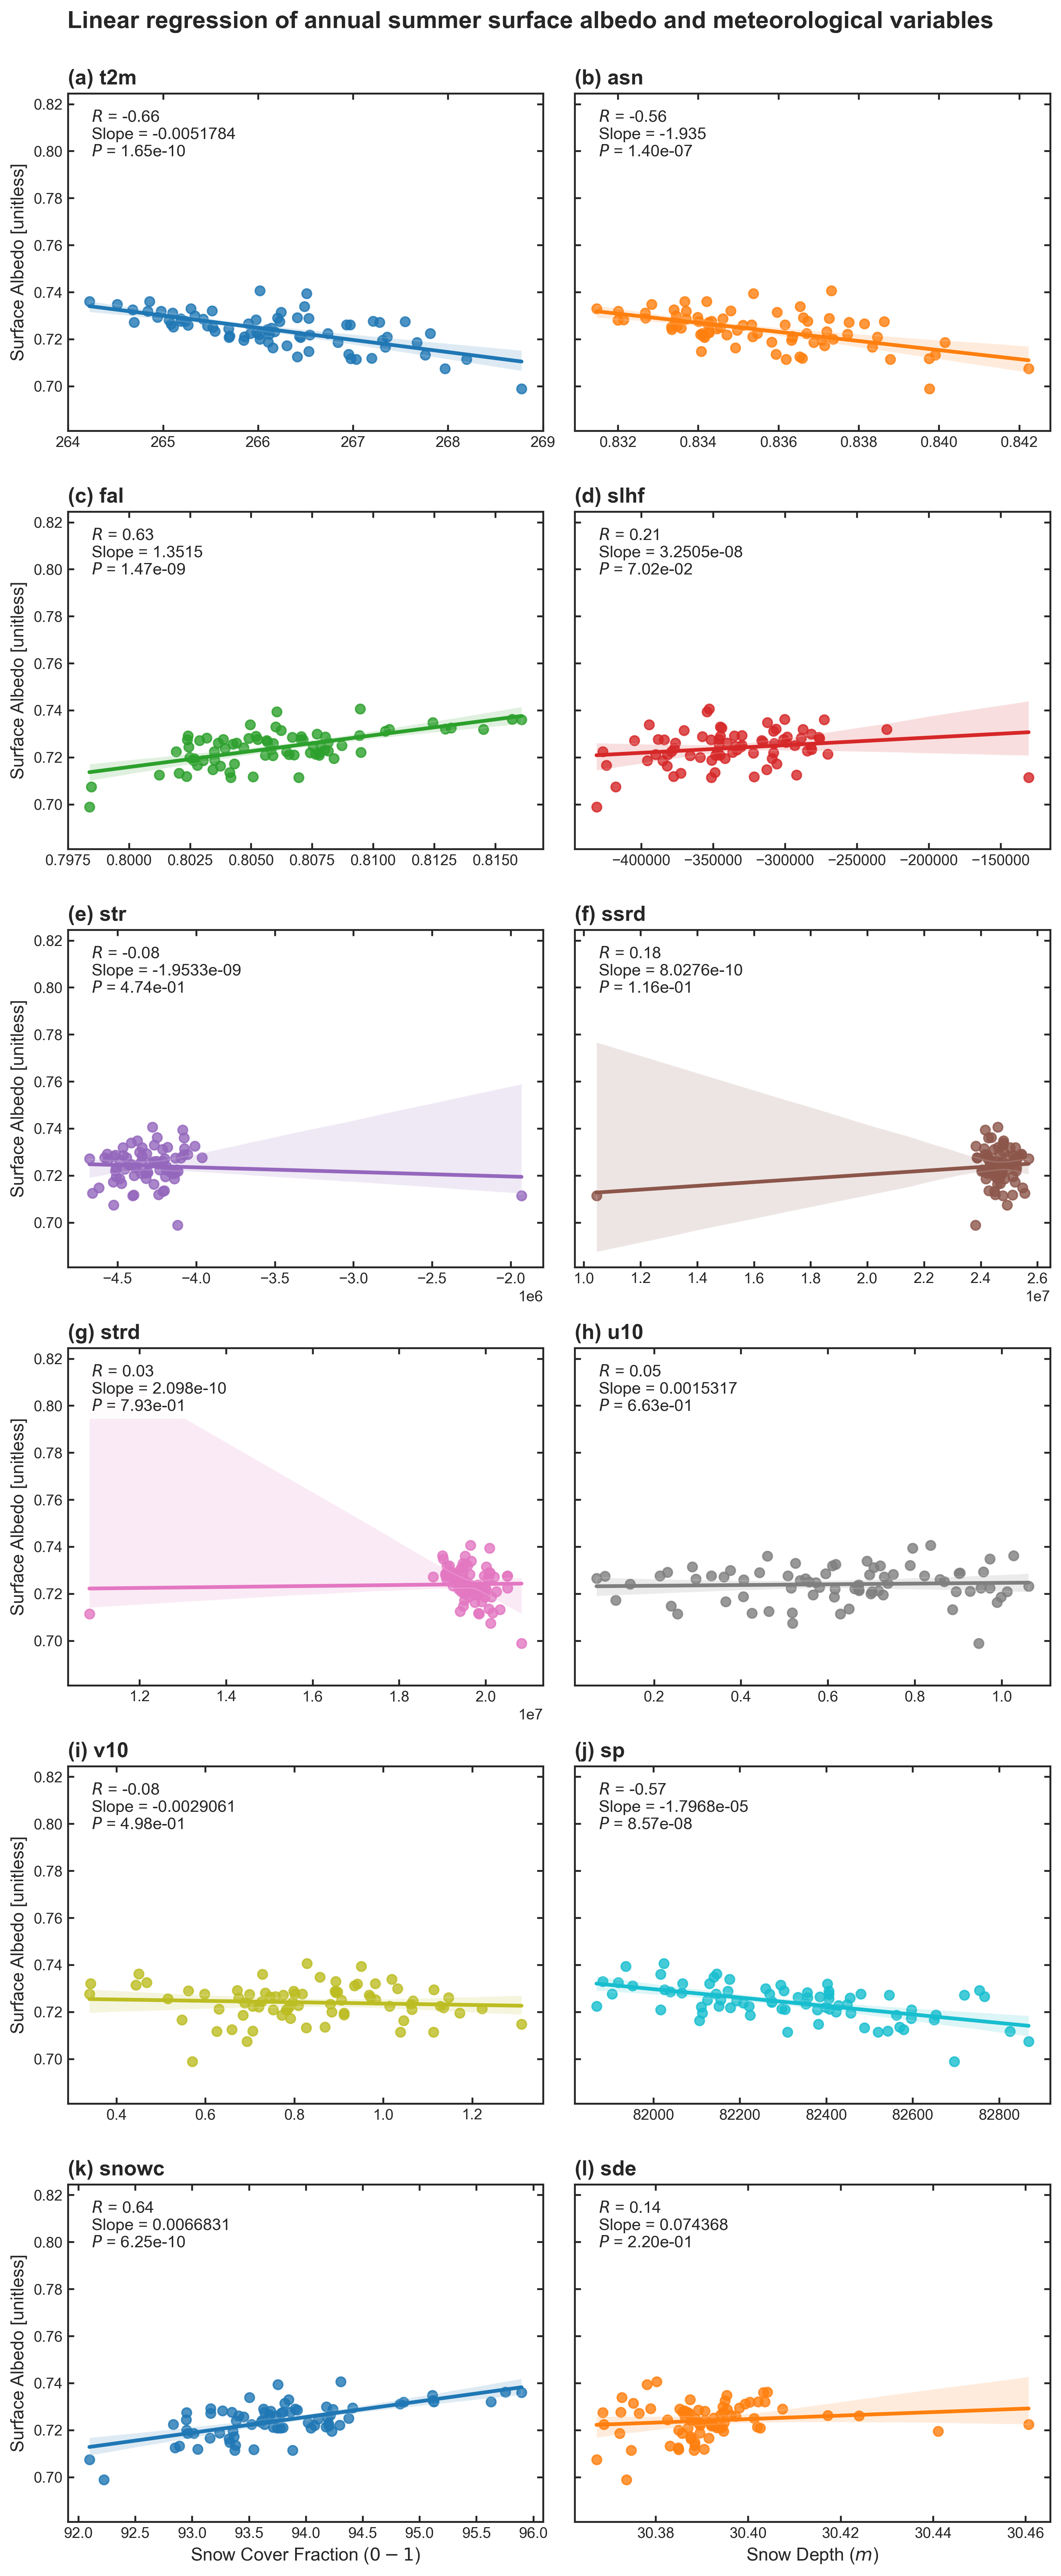

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# --- 0. 全局绘图风格和字体设置 (NPJ/Nature 风格) ---
sns.set_theme(style="ticks", rc={
    "axes.facecolor": "white", 
    "figure.facecolor": "white",
    "font.size": 12,        
    "axes.titlesize": 14,   
    "axes.labelsize": 12,   
    "xtick.labelsize": 10,  
    "ytick.labelsize": 10
})

# --- 1. 数据加载与列名定义 ---

# 替换为您的实际文件路径
file_path = "C:\\Users\\11823\\era5land\\era5_FAL_jja_timeseries.csv"

# 确定因变量 (Y) 的列名
y_col_name = 'Stacking model'

# X 变量列表 (12个变量)
x_cols = [
    't2m_JJA_Mean', 'asn_JJA_Mean', 'fal_JJA_Mean', 'slhf_JJA_Mean',
    'str_JJA_Mean', 'ssrd_JJA_Mean', 'strd_JJA_Mean', 'u10_JJA_Mean',
    'v10_JJA_Mean', 'sp_JJA_Mean', 'snowc_JJA_Mean', 'sde_JJA_Mean' 
]

try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"错误：文件未找到，请检查路径：{file_path}")
    exit()

# 提取数据
y_data = df[y_col_name]
x_col_datas = df[x_cols]
n_cols = len(x_cols) 


# --- 2. 绘图设置与标签精简 ---

colors = sns.color_palette("tab10", n_colors=n_cols)

# 关键修改：调整为 6 行 2 列的布局
fig, axes = plt.subplots(
    nrows=6, # 调整为 6 行
    ncols=2, # 调整为 2 列
    figsize=(10, 24), # 调整尺寸以适应高且窄的布局
    sharey=True,
    dpi=300
)
axes = axes.flatten()

# 定义全局标签
global_y_label = "Surface Albedo [unitless]"

# X 轴标签字典
x_label_map = {
    't2m_JJA_Mean': '2m Temperature ($K$)',
    'asn_JJA_Mean': 'Snow Area Fraction', 
    'fal_JJA_Mean': 'Surface Albedo [unitless]',
    'slhf_JJA_Mean': 'Latent Heat Flux ($J\,m^{-2}$)', 
    'str_JJA_Mean': 'Net Longwave Rad. ($J\,m^{-2}$)',
    'ssrd_JJA_Mean': 'Down Shortwave Rad. ($J\,m^{-2}$)',
    'strd_JJA_Mean': 'Down Longwave Rad. ($J\,m^{-2}$)',
    'u10_JJA_Mean': '10m U Wind ($m\,s^{-1}$)', 
    'v10_JJA_Mean': '10m V Wind ($m\,s^{-1}$)',
    'sp_JJA_Mean': 'Surface Pressure ($Pa$)',
    'snowc_JJA_Mean': 'Snow Cover Fraction ($0-1$)',
    'sde_JJA_Mean': 'Snow Depth ($m$)'
}

# 提取简短的标题/列名 (t2m, asn, fal...) 
short_x_names = [col.split('_')[0] for col in x_cols]


# --- 3. 循环回归与绘图 ---

for i, x_col in enumerate(x_cols):
    
    x_data = x_col_datas[x_col]
    
    # NaN值处理
    valid_mask = ~np.isnan(x_data) & ~np.isnan(y_data)
    
    if np.sum(valid_mask) < 2:
        print(f"警告：变量 {x_col} 有效数据点不足，跳过绘图。")
        continue

    x_valid = x_data[valid_mask]
    y_valid = y_data[valid_mask]

    # 1. 执行线性回归
    slope, intercept, r_value, p_value, std_err = linregress(x_valid, y_valid)
    r = r_value
    n = len(x_valid)
    
    # 2. 绘图
    ax = axes[i]
    color = colors[i]
    
    sns.regplot(
        x=x_valid, 
        y=y_valid, 
        ax=ax,
        color=color, 
        scatter_kws={'s': 40, 'alpha': 0.8}, 
        line_kws={'lw': 2.5}, 
        ci=95
    )

    # 3. 格式化图表
    # NPJ风格标题：(a) 变量缩写
    plot_label = chr(ord('a') + i) 
    ax.set_title(
        f"({plot_label}) {short_x_names[i]}", 
        loc='left', 
        fontsize=14, 
        fontweight='bold'
    )
    
    # 轴标签
    # i % 2 == 0 确保只有每行的第一张图（左侧一列）有 Y 轴标签 (2列)
    if i % 2 == 0: 
        ax.set_ylabel(global_y_label, fontsize=12)
    else:
        ax.set_ylabel("") 
        
    # i >= 10 确保只有底行（第6行）的图有 X 轴标签 (索引 10, 11)
    if i >= 10: 
        ax.set_xlabel(x_label_map[x_col], fontsize=12)
    else:
        ax.set_xlabel("")
        
    ax.tick_params(axis='both', direction='in', top=True, right=True, length=4) 

    # 4. 添加回归统计信息到图上
    text_content = (
        f"$R$ = {r:.2f}\n" 
        f"Slope = {slope:.5g}\n"
        f"$P$ = {p_value:.2e}"
    )
    
    ax.text(
        0.05, 0.95, text_content, 
        transform=ax.transAxes, 
        fontsize=11, 
        verticalalignment='top', 
        bbox=dict(boxstyle="square,pad=0.3", fc="white", alpha=0.9, ec="none")
    )


# 5. 调整布局并保存/显示
plt.tight_layout(rect=[0, 0, 1, 0.98]) # 调整 rect 以适应高图
plt.suptitle(
    "Linear regression of annual summer surface albedo and meteorological variables",
    fontsize=16, 
    fontweight='bold', 
    y=0.995 # 标题位置调整到顶部
)

plt.show()
# plt.savefig("regression_analysis_6x2_npj_style.png", dpi=300, bbox_inches='tight')

C:\Users\11823\AppData\Local\Temp\ipykernel_35808\1379715929.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


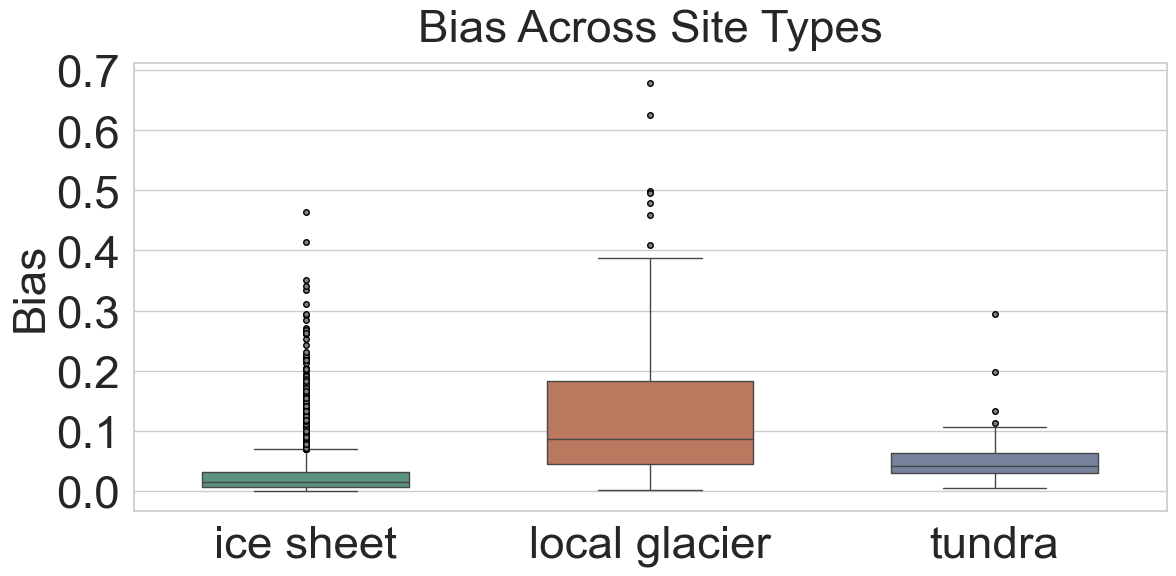

In [15]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ===== 参数区 =====
CSV_PATH = r"C:\greenland\1995bu\model&station_distance_with_type.csv"
FONT_SIZE = 33
FIG_SIZE = (12, 6)
TITLE = "Bias Across Site Types"  # ← 图标题（可中英双语）
ROTATION = 0  # ← 改为0表示x轴文字水平

# ===== 读数据 =====
df = pd.read_csv(CSV_PATH, usecols=["bias", "type"])

# ===== 绘图风格 =====
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=FIG_SIZE)

# 深色调色板
palette = sns.color_palette("Set2", 3)
palette = [(r*0.8, g*0.8, b*0.8) for (r, g, b) in palette]

# 实心小圆点
flierprops = dict(marker='o', markersize=4, markerfacecolor='grey', markeredgecolor='black')

# ===== 绘图 =====
ax = sns.boxplot(
    x="type",
    y="bias",
    data=df,
    width=0.6,
    palette=palette,
    showfliers=True,
    flierprops=flierprops
)

# ===== 美化 =====
ax.set_title(TITLE, fontsize=FONT_SIZE, pad=15)
ax.set_xlabel("")  # 去掉x轴标题
ax.set_ylabel("Bias", fontsize=FONT_SIZE)
ax.tick_params(axis='x', labelsize=FONT_SIZE, rotation=ROTATION)
ax.tick_params(axis='y', labelsize=FONT_SIZE)

# 设置y轴每隔0.1一条主刻度
ymax = np.ceil(df["bias"].max() * 10) / 10
ax.set_yticks(np.arange(0, ymax + 0.1, 0.1))

plt.tight_layout()
plt.show()


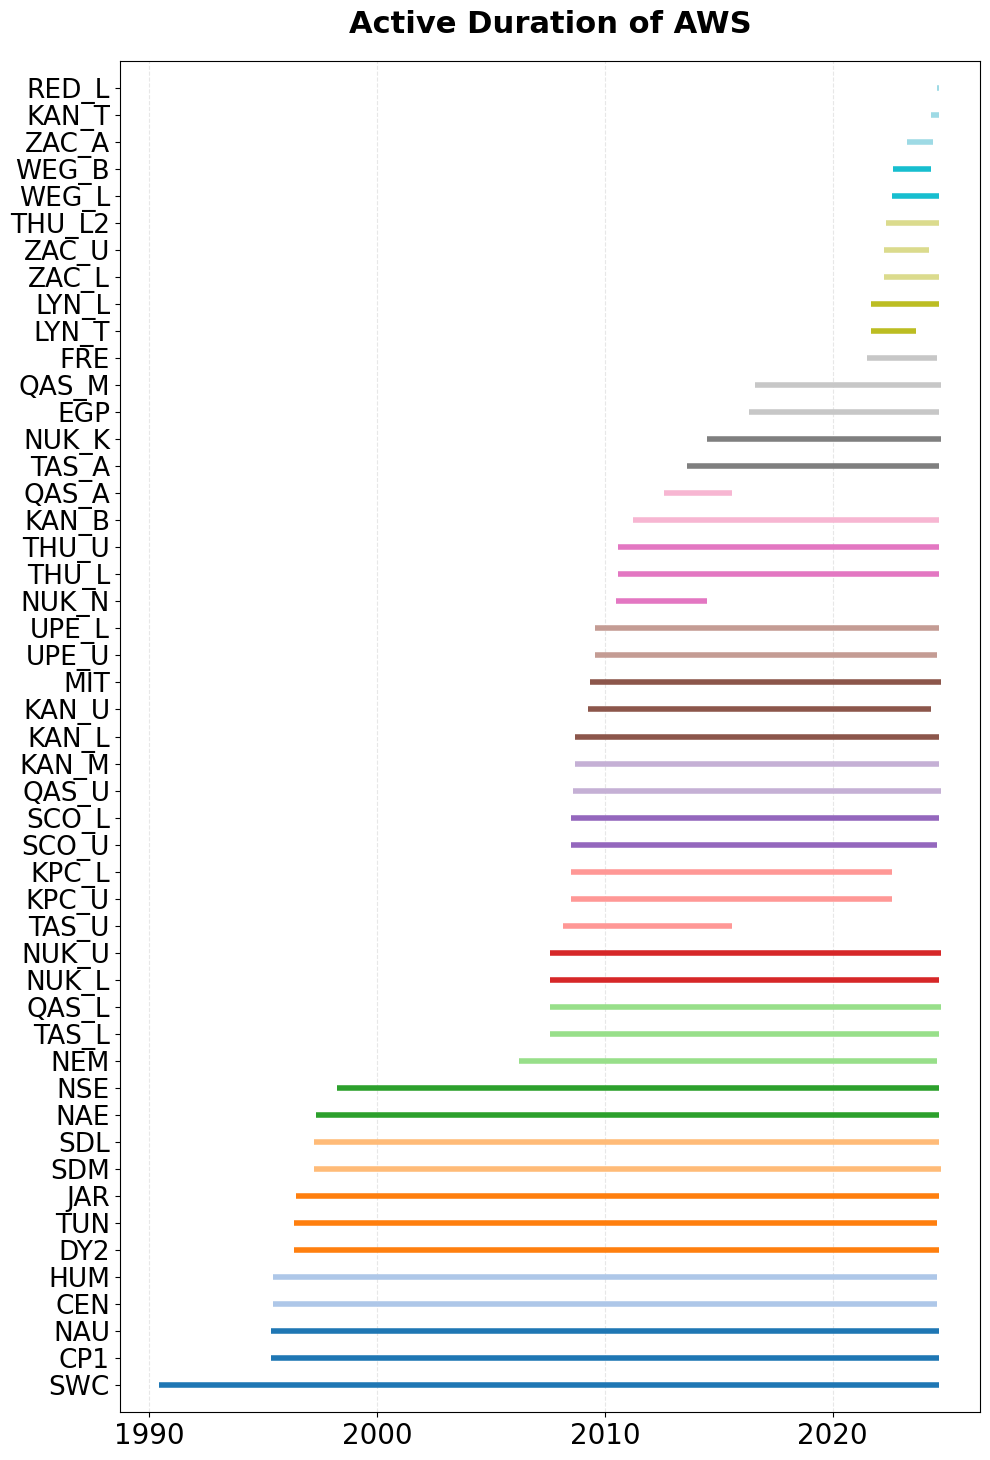

站点数据跨度统计:
SWC             | 1990-06 至 2024-09 | 34.3年 | 190个数据点
CP1             | 1995-05 至 2024-09 | 29.3年 | 162个数据点
NAU             | 1995-05 至 2024-09 | 29.3年 | 185个数据点
CEN             | 1995-06 至 2024-08 | 29.2年 | 105个数据点
HUM             | 1995-06 至 2024-08 | 29.2年 | 128个数据点
DY2             | 1996-05 至 2024-09 | 28.3年 | 214个数据点
TUN             | 1996-05 至 2024-08 | 28.3年 | 154个数据点
JAR             | 1996-06 至 2024-09 | 28.3年 | 161个数据点
SDM             | 1997-04 至 2024-10 | 27.5年 | 206个数据点
SDL             | 1997-04 至 2024-09 | 27.4年 | 200个数据点
NAE             | 1997-05 至 2024-09 | 27.3年 | 151个数据点
NSE             | 1998-04 至 2024-09 | 26.4年 | 182个数据点
NEM             | 2006-04 至 2024-08 | 18.3年 | 104个数据点
TAS_L           | 2007-08 至 2024-09 | 17.1年 | 105个数据点
QAS_L           | 2007-08 至 2024-10 | 17.2年 | 146个数据点
NUK_L           | 2007-08 至 2024-09 | 17.1年 | 120个数据点
NUK_U           | 2007-08 至 2024-10 | 17.2年 | 115个数据点
TAS_U           | 2008-03 至 2015-08 | 7.4年 | 48个数据点
KPC_U           | 20

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

# 读取CSV文件
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
df = pd.read_csv(file_path)

# 筛选出有albedo数据的行（非空值）
df_albedo = df[df['albedo'].notna()].copy()

# 创建日期列（假设每月1号）
df_albedo['date'] = pd.to_datetime(df_albedo['year'].astype(str) + '-' + 
                                    df_albedo['month'].astype(str) + '-01')

# 按站点分组，获取每个站点的时间跨度
station_ranges = []
for station, group in df_albedo.groupby('station'):
    min_date = group['date'].min()
    max_date = group['date'].max()
    station_ranges.append({
        'station': station,
        'start': min_date,
        'end': max_date,
        'data_points': len(group)
    })

# 转换为DataFrame并按开始时间排序
ranges_df = pd.DataFrame(station_ranges)
ranges_df = ranges_df.sort_values('start')

# 创建图形
fig, ax = plt.subplots(figsize=(10, max(8, len(ranges_df) * 0.3)))

# 绘制每个站点的时间跨度
colors = plt.cm.tab20(np.linspace(0, 1, len(ranges_df)))

for idx, (_, row) in enumerate(ranges_df.iterrows()):
    ax.plot([row['start'], row['end']], [idx, idx], 
            linewidth=4, solid_capstyle='butt', 
            color=colors[idx], label=row['station'])
    


# 设置图形属性
ax.set_ylim(-1, len(ranges_df))
ax.set_xlabel('', fontsize=16, fontweight='bold')
ax.set_ylabel('', fontsize=16, fontweight='bold')
ax.set_title('Active Duration of AWS', 
             fontsize=22, fontweight='bold', pad=20)

# 设置y轴刻度（站点名称）
ax.set_yticks(range(len(ranges_df)))
ax.set_yticklabels(ranges_df['station'].values, fontsize=19)

# 设置x轴刻度：1990-2020，每隔十年
x_ticks = pd.date_range(start='1990-01-01', end='2020-01-01', freq='10YS')
ax.set_xticks(x_ticks)
ax.set_xticklabels([date.year for date in x_ticks], fontsize=20)

# 美化网格
ax.grid(True, axis='x', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)

# x轴日期标签水平显示
plt.setp(ax.xaxis.get_majorticklabels(), rotation=0)

# 调整布局
plt.tight_layout()

# 显示图形
plt.show()

# 打印统计信息
print("=" * 60)
print("站点数据跨度统计:")
print("=" * 60)
for _, row in ranges_df.iterrows():
    duration = (row['end'] - row['start']).days / 365.25
    print(f"{row['station']:15s} | {row['start'].strftime('%Y-%m')} 至 "
          f"{row['end'].strftime('%Y-%m')} | "
          f"{duration:.1f}年 | {row['data_points']}个数据点")
print("=" * 60)

In [ ]:
# -*- coding: utf-8 -*-
"""
Greenland AWS distribution map with realistic basemap
(ice sheet / local glacier / tundra)
"""

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patheffects as PathEffects

# ===== 路径 =====
csv_path = r"C:\Users\greenlandProject\document\newdata\dataverse_files\dataverse_files\AWS_metadata.csv"
greenland_shp = r"C:\greenland\Greenland_shp\Gboundry.shp"  # 你的格陵兰边界 shapefile

# ===== 读取数据 =====
df = pd.read_csv(csv_path)
df = df[df["location_type"].isin(["ice sheet", "local glacier", "tundra"])]

# 颜色匹配箱线图
colors = {
    "ice sheet": "#4DB6AC",     # 绿色偏青
    "local glacier": "#C97B63", # 棕橘色
    "tundra": "#707C8B"         # 冷灰蓝
}

# ===== 绘图设置 =====
proj = ccrs.NorthPolarStereo()
fig = plt.figure(figsize=(8, 10))
ax = plt.axes(projection=proj)
ax.set_extent([-75, -10, 58, 85], crs=ccrs.PlateCarree())

# ===== 背景与地形特征 =====
ax.stock_img()  # 自带自然底图
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, color='k', zorder=1)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.3, zorder=1)
ax.add_feature(cfeature.LAKES, alpha=0.3, facecolor='lightblue', zorder=0)

# 加入格陵兰边界
gdf = gpd.read_file(greenland_shp).to_crs("EPSG:4326")
ax.add_geometries(gdf.geometry, crs=ccrs.PlateCarree(),
                  facecolor='none', edgecolor='black', linewidth=1.2, zorder=2)

# ===== 绘制站点 =====
for typ, sub in df.groupby("location_type"):
    ax.scatter(sub["longitude"], sub["latitude"],
               color=colors[typ], edgecolor='black', linewidth=0.6,
               s=75, marker='o', transform=ccrs.PlateCarree(),
               label=typ.capitalize(), zorder=3)

# ===== 添加文字标签（可选） =====
for _, row in df.iterrows():
    txt = ax.text(row["longitude"]+0.3, row["latitude"]+0.15, row["stid"],
                  transform=ccrs.PlateCarree(), fontsize=7, weight="bold", color='k', zorder=4)
    txt.set_path_effects([PathEffects.withStroke(linewidth=1.5, foreground="white")])

# ===== 经纬网与图例 =====
gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray', alpha=0.4)
gl.top_labels = gl.right_labels = False
gl.xlabel_style = {'size': 9}
gl.ylabel_style = {'size': 9}

plt.legend(loc='lower left', frameon=False, fontsize=10, title="Site type")
plt.title("Automatic Weather Stations across Greenland", fontsize=13, pad=10)
plt.tight_layout()
plt.savefig(r"C:\greenland\AWS_Map_Greenland.png", dpi=400)
plt.show()
